# 05 — Grad-CAM Explainability

Visualise which retinal regions drive each DR severity prediction using
Gradient-weighted Class Activation Mapping (Grad-CAM).

Critical for:
- **Clinical trust**: doctors need to see _why_ the model predicts a severity level
- **Model debugging**: verify the model focuses on lesions, not artifacts
- **Failure analysis**: understand misclassifications


In [1]:
import importlib
import os
import sys

IS_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in dir() else False

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/diabetic_retinopathy"
    %pip install -q timm albumentations kaggle
else:
    PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import src.config
importlib.reload(src.config)
from src import config


/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.augmentations import get_valid_transforms
from src.dataset import DRDataset, load_and_split_dataframe
from src.gradcam import GradCAMExplainer, generate_gradcam_grid
from src.model import build_model
from src.utils import get_device, seed_everything

seed_everything()
device = get_device()


Using GPU: NVIDIA H200 (150.1 GB)


## 1. Load Model + Data


In [3]:
# Load APTOS fine-tuned model
model = build_model(pretrained=False)

ckpt_path = os.path.join(config.CHECKPOINTS_DIR, "best_model_aptos_finetune.pth")
if not os.path.isfile(ckpt_path):
    ckpt_path = os.path.join(config.CHECKPOINTS_DIR, "best_model_s1_phase3.pth")
    print(f"APTOS checkpoint not found, using Stage 1: {ckpt_path}")

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
model = model.to(device)
model.eval()

print(f"Loaded: {os.path.basename(ckpt_path)}")
# Checkpoints from Trainer store validation QWK as metrics["kappa"] (not top-level "qwk")
_val_qwk = (ckpt.get("metrics") or {}).get("kappa")
print(f"  QWK: {_val_qwk:.4f}" if _val_qwk is not None else "  QWK: N/A")


Loaded: best_model_aptos_finetune.pth
  QWK: 0.7725


In [4]:
# Load APTOS test data for cleaner Grad-CAM visualisations
_, _, test_df = load_and_split_dataframe(dataset_name="aptos")

CLASS_CODE = dict(enumerate(config.CLASS_NAMES))
print(f"Test images: {len(test_df)}")
print(f"Class distribution:")
print(test_df["level"].value_counts().sort_index())


Test images: 550
Class distribution:
level
0    271
1     56
2    150
3     29
4     44
Name: count, dtype: int64


## 2. Initialise Grad-CAM


In [5]:
explainer = GradCAMExplainer(model, device=device)
print(f"Target layer: {explainer.target_layer}")


Target layer: Sequential(
  (0): InvertedResidual(
    (conv_pw): Conv2d(160, 960, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      960, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (conv_dw): Conv2dSame(960, 960, kernel_size=(3, 3), stride=(2, 2), groups=960, bias=False)
    (bn2): BatchNormAct2d(
      960, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (aa): Identity()
    (se): SqueezeExcite(
      (conv_reduce): Conv2d(960, 40, kernel_size=(1, 1), stride=(1, 1))
      (act1): SiLU(inplace=True)
      (conv_expand): Conv2d(40, 960, kernel_size=(1, 1), stride=(1, 1))
      (gate): Sigmoid()
    )
    (conv_pwl): Conv2d(960, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNormAct2d(
      256, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
      (drop):

## 3. Single-Image Grad-CAM

Generate heatmaps for one image per DR severity level.


/tmp/ipykernel_49152/1895514207.py:54: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_49152/1895514207.py:54: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_49152/1895514207.py:55: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.savefig(os.path.join(config.FIGURES_DIR, "gradcam_per_class.png"), dpi=200, bbox_inches="tight")
/tmp/ipykernel_49152/1895514207.py:55: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.savefig(os.path.join(config.FIGURES_DIR, "gradcam_per_class.png"), dpi=200, bbox_inches="tight")
/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/teamspace/studios/thi

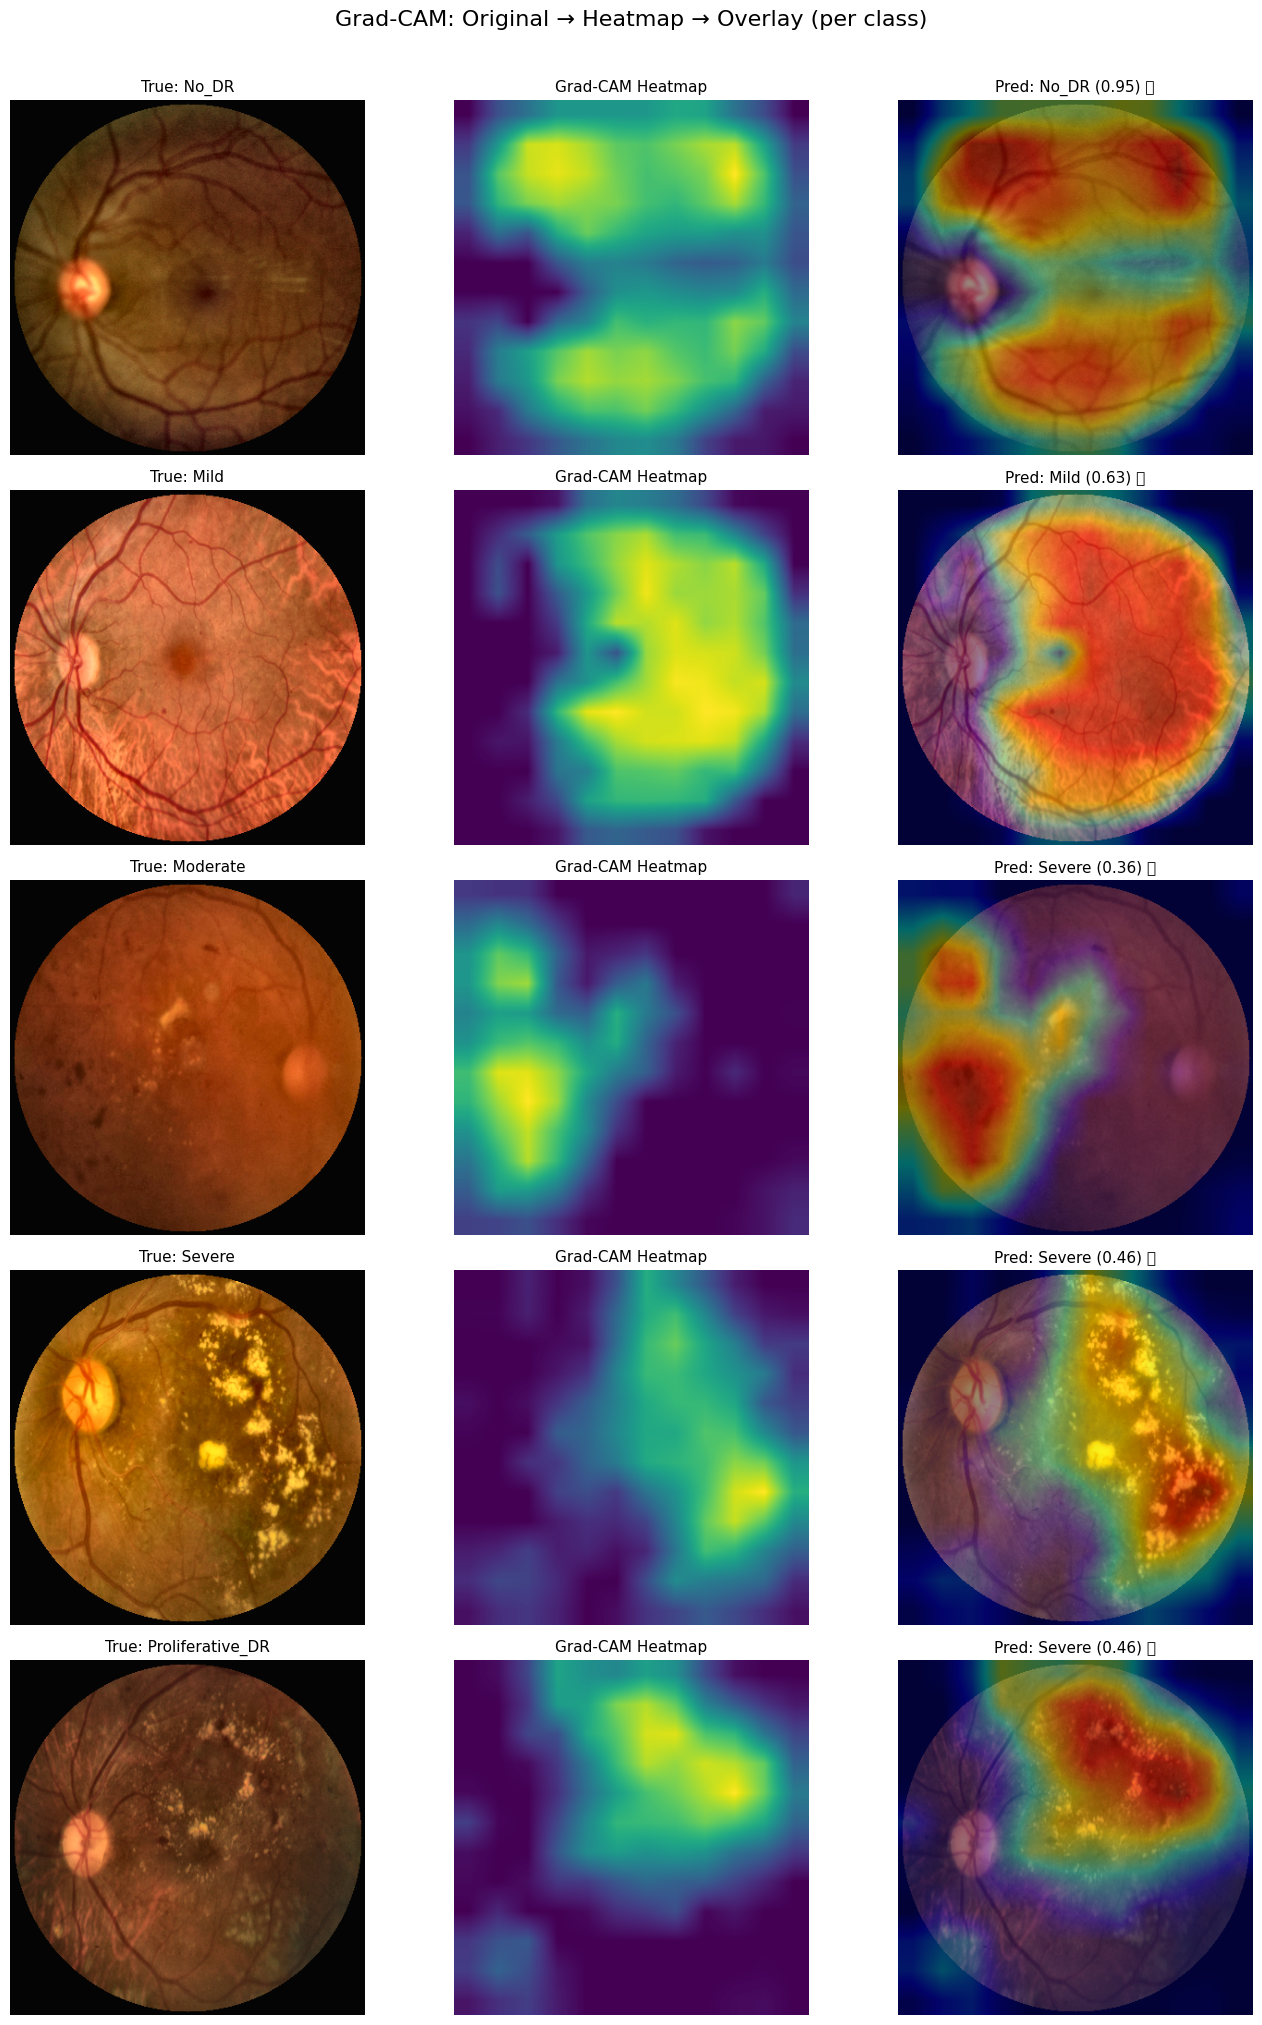

In [6]:
def find_image(images_dir, image_id):
    """Try common extensions and return the file path, or None."""
    for ext in (".jpeg", ".jpg", ".png", ".JPEG", ".JPG"):
        p = os.path.join(images_dir, image_id + ext)
        if os.path.isfile(p):
            return p
    return None


def load_sample_image(image_id):
    """Load image from APTOS (preprocessed cache or raw)."""
    # Try preprocessed cache first
    cache_dir = os.path.join(config.APTOS_DATA_DIR, f"preprocessed_{config.IMG_SIZE}_aptos")
    path = find_image(cache_dir, image_id)
    if path is None:
        path = find_image(config.APTOS_IMAGES_DIR, image_id)
    if path is None:
        return None
    bgr = cv2.imread(path)
    if bgr is None:
        return None
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


fig, axes = plt.subplots(config.NUM_CLASSES, 3, figsize=(14, 4 * config.NUM_CLASSES))
fig.suptitle("Grad-CAM: Original → Heatmap → Overlay (per class)", fontsize=16, y=1.01)

for cls in range(config.NUM_CLASSES):
    subset = test_df[test_df["level"] == cls]
    if len(subset) == 0:
        continue
    sample = subset.iloc[0]
    img_rgb = load_sample_image(sample["image"])
    if img_rgb is None:
        print(f"  Class {cls}: image not found, skipping")
        continue

    heatmap, overlay, pred_class, proba = explainer.explain(img_rgb)

    axes[cls, 0].imshow(img_rgb)
    axes[cls, 0].set_title(f"True: {CLASS_CODE[cls]}", fontsize=11)
    axes[cls, 0].axis("off")

    axes[cls, 1].imshow(heatmap)
    axes[cls, 1].set_title("Grad-CAM Heatmap", fontsize=11)
    axes[cls, 1].axis("off")

    pred_name = CLASS_CODE[pred_class]
    correct = "✅" if pred_class == cls else "❌"
    axes[cls, 2].imshow(overlay)
    axes[cls, 2].set_title(f"Pred: {pred_name} ({proba[pred_class]:.2f}) {correct}", fontsize=11)
    axes[cls, 2].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(config.FIGURES_DIR, "gradcam_per_class.png"), dpi=200, bbox_inches="tight")
plt.show()


## 4. Grad-CAM Grid

Multiple images per class to identify consistent attention patterns.


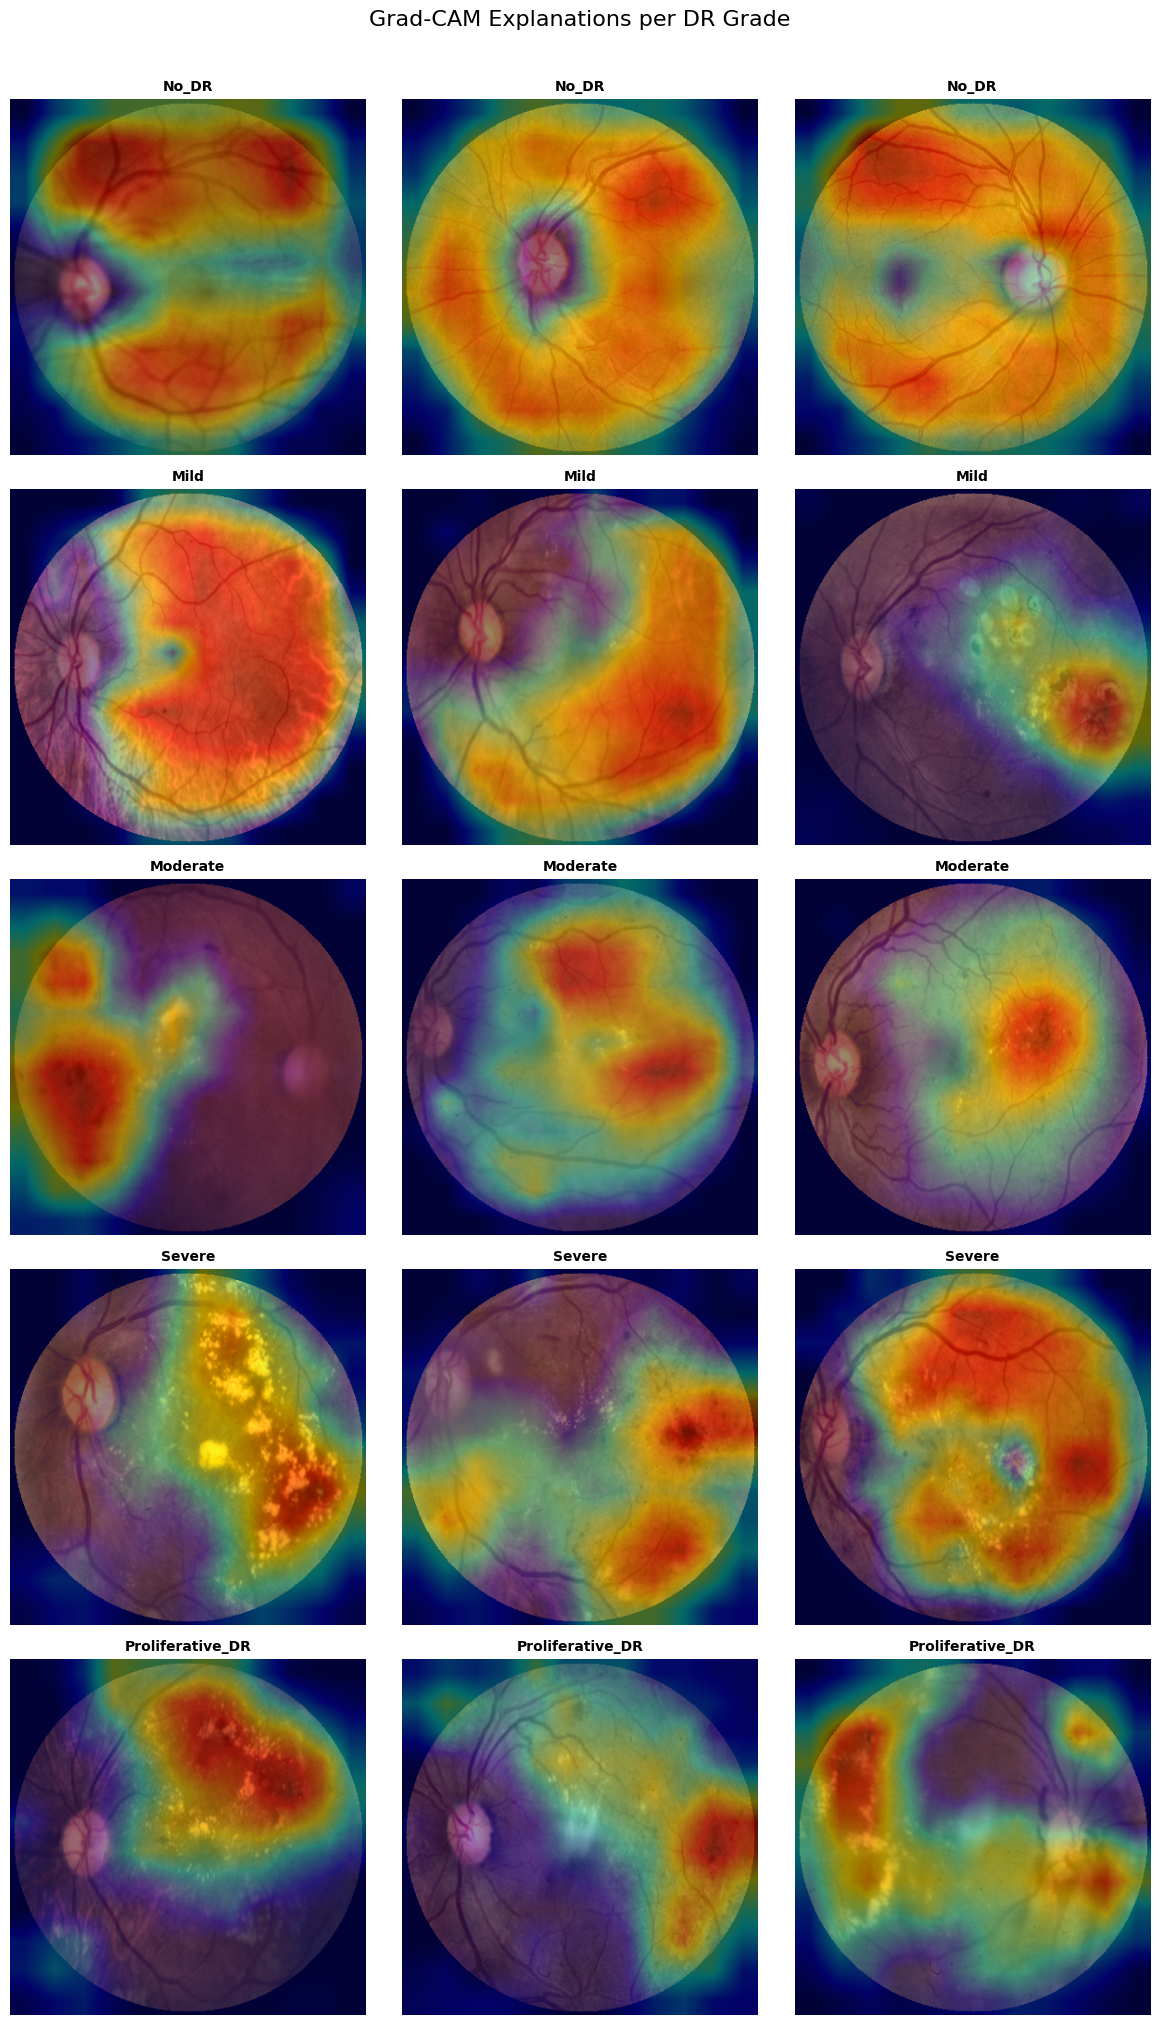

In [7]:
fig = generate_gradcam_grid(
    explainer=explainer,
    test_df=test_df,
    images_dir=config.APTOS_IMAGES_DIR,
    n_per_class=3,
    save_path=os.path.join(config.FIGURES_DIR, "gradcam_grid.png"),
)
plt.show()


## 5. Misclassification Analysis

Focus Grad-CAM on misclassified images to understand failure modes.


2026-05-01 08:57:03 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_384_aptos


Misclassified: 115 / 550 (20.9%)


/tmp/ipykernel_49152/1440762670.py:50: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_49152/1440762670.py:51: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.savefig(os.path.join(config.FIGURES_DIR, "gradcam_misclassified.png"), dpi=200, bbox_inches="tight")


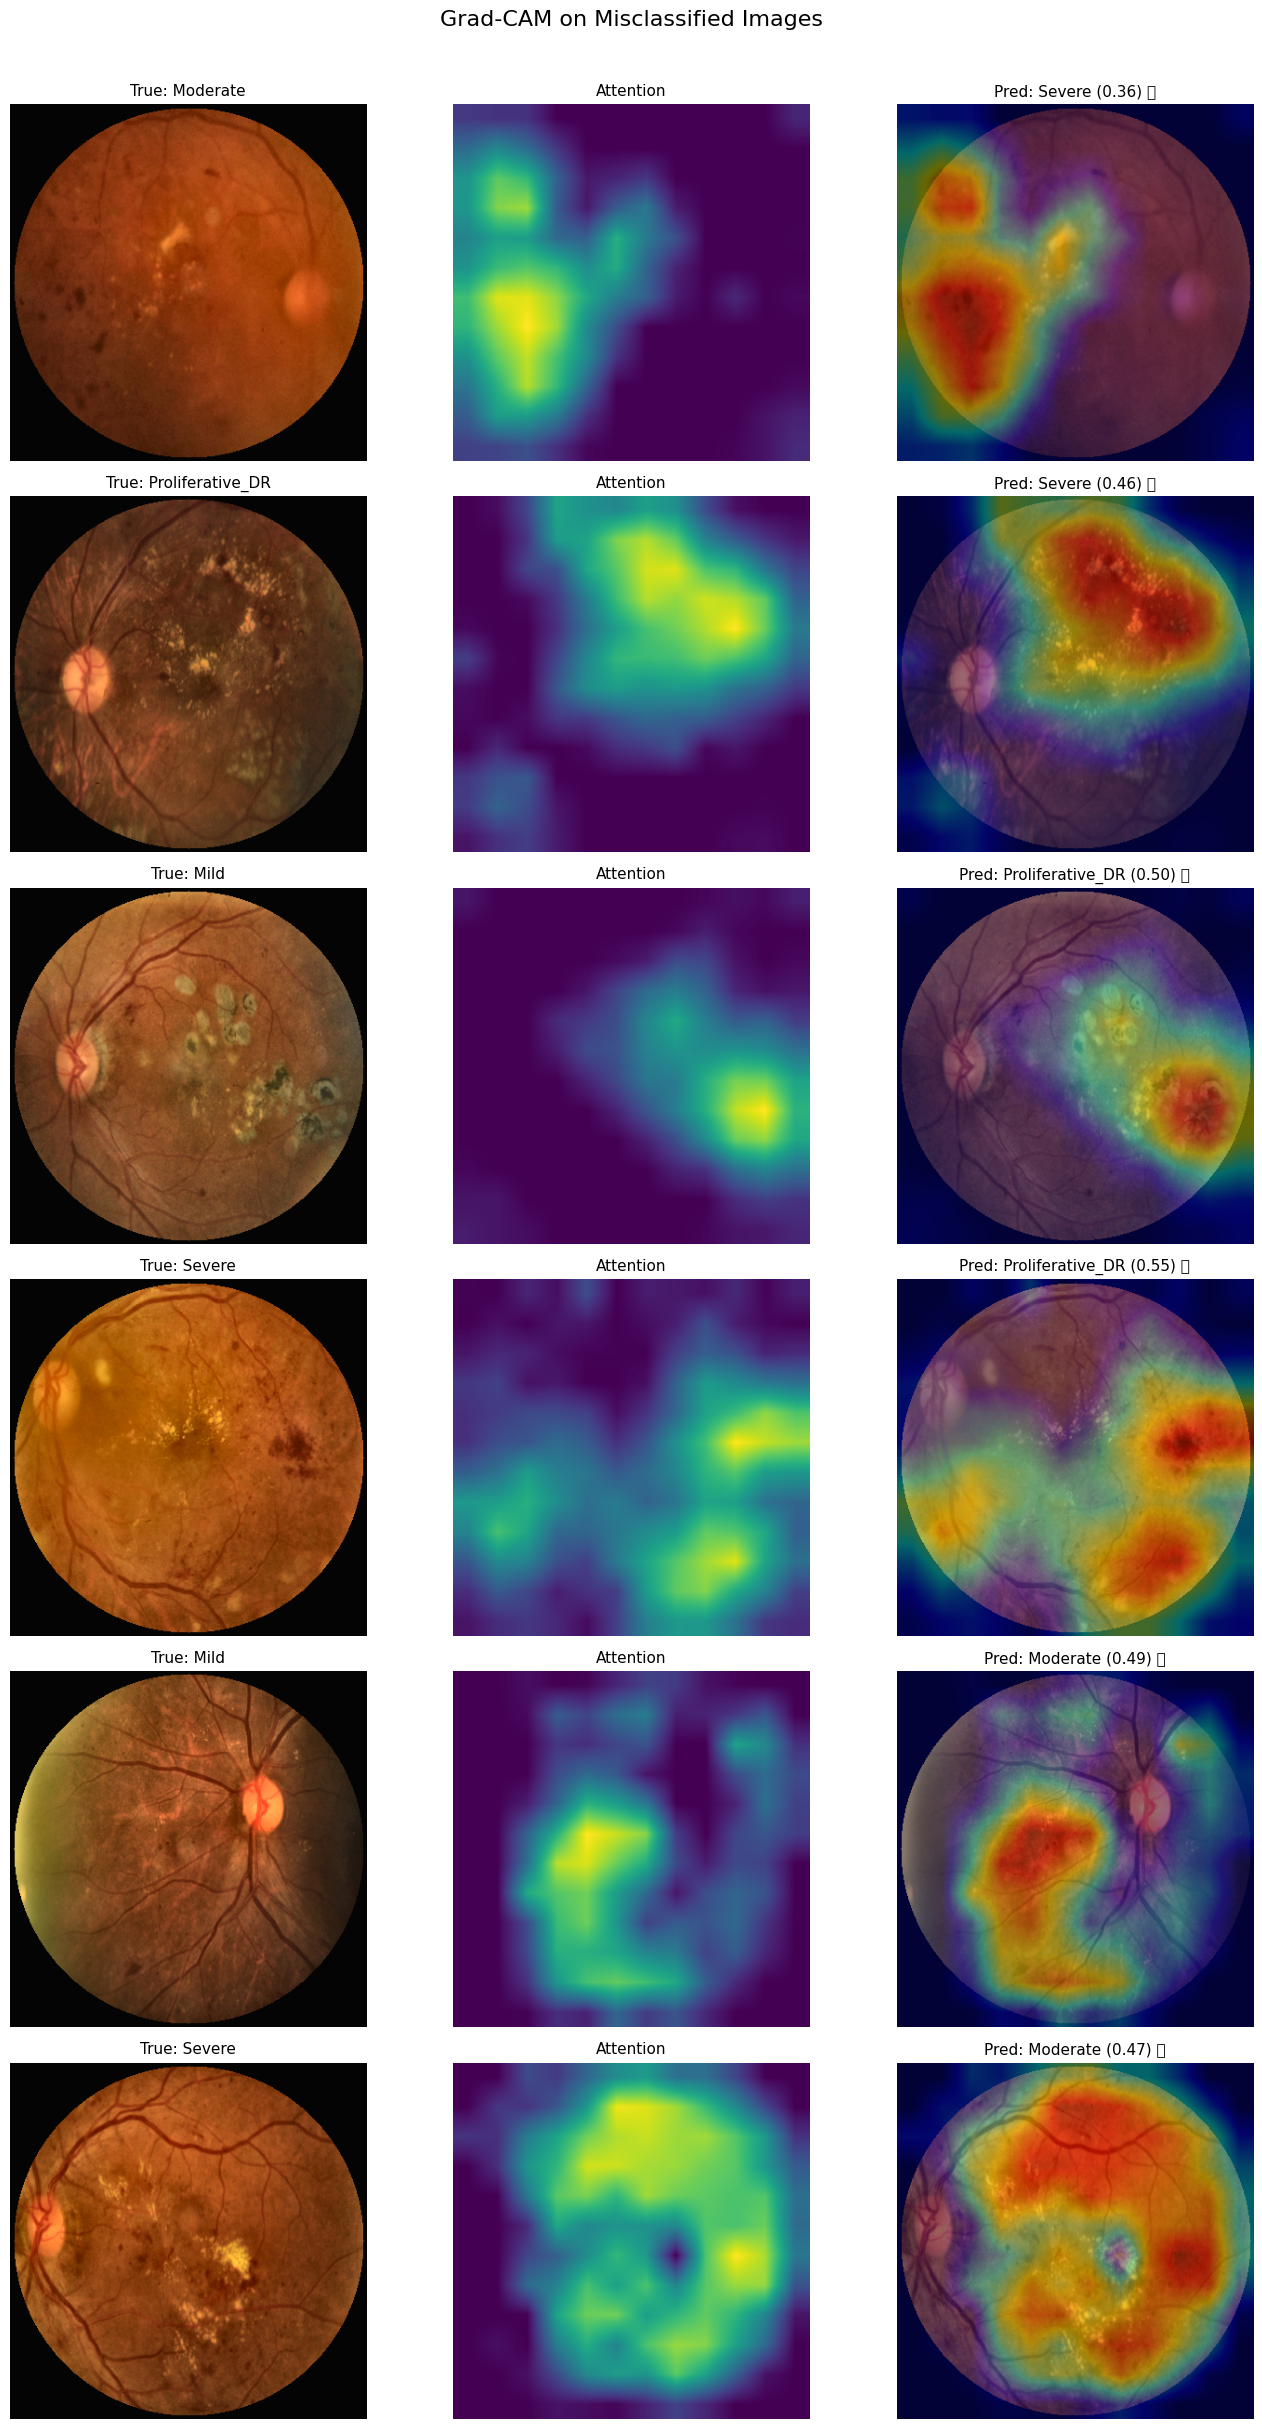

In [8]:
from src.evaluate import predict

# Get predictions on test set
valid_tfm = get_valid_transforms(config.IMG_SIZE)
test_dataset = DRDataset(
    test_df,
    dataset_name="aptos",
    transform=valid_tfm,
    preprocessing=False,
)
test_loader = torch.utils.data.DataLoader(
    test_dataset, batch_size=config.STAGE2_BATCH_SIZE, shuffle=False,
    num_workers=config.NUM_WORKERS, pin_memory=config.PIN_MEMORY,
)

y_true, y_pred, y_proba = predict(model, test_loader, device)

# Find misclassified
misclassified_idx = np.where(np.array(y_true) != np.array(y_pred))[0]
print(f"Misclassified: {len(misclassified_idx)} / {len(y_true)} ({100*len(misclassified_idx)/len(y_true):.1f}%)")

# Show Grad-CAM for up to 6 misclassified images
n_show = min(6, len(misclassified_idx))
if n_show > 0:
    fig, axes = plt.subplots(n_show, 3, figsize=(14, 4 * n_show))
    if n_show == 1:
        axes = axes.reshape(1, -1)
    fig.suptitle("Grad-CAM on Misclassified Images", fontsize=16, y=1.01)

    for i, idx in enumerate(misclassified_idx[:n_show]):
        row = test_df.iloc[idx]
        img_rgb = load_sample_image(row["image"])
        if img_rgb is None:
            continue

        heatmap, overlay, pred_cls, proba = explainer.explain(img_rgb)

        axes[i, 0].imshow(img_rgb)
        axes[i, 0].set_title(f"True: {CLASS_CODE[int(y_true[idx])]}", fontsize=11)
        axes[i, 0].axis("off")

        axes[i, 1].imshow(heatmap)
        axes[i, 1].set_title("Attention", fontsize=11)
        axes[i, 1].axis("off")

        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title(f"Pred: {CLASS_CODE[int(y_pred[idx])]} ({proba[pred_cls]:.2f}) ❌", fontsize=11)
        axes[i, 2].axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(config.FIGURES_DIR, "gradcam_misclassified.png"), dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("No misclassifications! Perfect accuracy.")


## 6. Attention Statistics

Measure how much of the Grad-CAM activation falls on the central fundus region
versus the periphery.


In [9]:
# Compute attention distribution stats across test set
central_ratios = []
n_analyze = min(50, len(test_df))

for i in range(n_analyze):
    row = test_df.iloc[i]
    img_rgb = load_sample_image(row["image"])
    if img_rgb is None:
        continue

    heatmap, _, _, _ = explainer.explain(img_rgb)

    # Convert heatmap to grayscale
    heatmap_gray = np.mean(heatmap, axis=2) if heatmap.ndim == 3 else heatmap
    h, w = heatmap_gray.shape

    # Central region (60% of image)
    margin_h, margin_w = int(h * 0.2), int(w * 0.2)
    central = heatmap_gray[margin_h:h-margin_h, margin_w:w-margin_w]

    total_activation = heatmap_gray.sum()
    if total_activation > 0:
        central_ratio = central.sum() / total_activation
        central_ratios.append(central_ratio)

if central_ratios:
    print(f"Analyzed {len(central_ratios)} images")
    print(f"Central attention ratio: {np.mean(central_ratios):.3f} ± {np.std(central_ratios):.3f}")
    print("  (1.0 = all attention on center, 0.0 = all on edges)")
    print("  Values > 0.5 indicate the model focuses on the retinal region, not edges/artifacts")


Analyzed 50 images
Central attention ratio: 0.507 ± 0.102
  (1.0 = all attention on center, 0.0 = all on edges)
  Values > 0.5 indicate the model focuses on the retinal region, not edges/artifacts
